# Change model parameters
Understand which parameter can i change in a nn model.

## Lib and data

In [78]:
# Libs

import torch # the main pytorch library
from torch import nn # the sub-library containing neural networks
from torch.utils.data import DataLoader, Subset # an object that generates batches of data for training/testing
from torchvision import datasets # popular datasets, architectures and common image transformations
from torchvision.transforms import ToTensor # an easy way to convert PIL images to Tensors

import numpy as np # NumPy, the python array library
import random # for generating random numbers
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split


In [79]:
# Set seeds

SEED = 0 # seed for reproducibility

random.seed(SEED) # set the seed for random numbers
np.random.seed(SEED) # set the seed for numpy arrays

In [80]:
# Download training data
# Build validation data
# Download test data

# Parameters
validation_ratio = 0.2

# Download training data from open datasets
training_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=True,  # this is the training data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Split dataset into training and validation sets
# train and validation data
num_samples = len(training_data)
num_validation_samples = int(validation_ratio * num_samples)
num_training_samples = num_samples - num_validation_samples

# First num_training_samples are for training 
# Last num_validation_samples are for validation
train_data = Subset(training_data, range(num_training_samples))
validation_data = Subset(training_data, range(num_training_samples, num_samples))



# Download test data from open datasets
test_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=False,  # this is the test data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


In [81]:
# Define data loader (specifing batch size)

batch_size = 64 # the size of input data took for one iteration

# Create data loaders.
# Create data loaders
train_dataloader = DataLoader(train_data, batch_size=batch_size)
validation_dataloader = DataLoader(validation_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# N is batch size; 
# C is number of channels;
# H is height of image; 
# W is width of image
for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in validation_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break



Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [82]:
# Set the device 
device = ( # check if gpu is available
    "cuda"
    if torch.cuda.is_available() # use gpu
    else "mps" # use mps
    if torch.backends.mps.is_available() # use mps
    else "cpu" # use cpu
)
print(f"Using {device} device\n")

Using cpu device



## The model

**The model:** 

The **Flatten** layer translates a multi dimensional tensor into a single dimensional tensor. 
For instance, a pic of size (N,C,W,H) becomes (N,C * W * H) where N is the batch size, C is the number of channels, W is the weights of the pic and H is the height of the pic. \


**Linear** is a layer of a fully connected (dense) linear layer, where the first entry is the number of units of the input and the second entry is the number of units of the output. 

**Sequential** is a way to define a sequence of layers of a nn.

In [83]:
# Define model
# Create an instance of the model

class NeuralNetwork_1(nn.Module): # define a neural network class
    def __init__(self): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(28*28, 512), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            nn.ReLU(),  # activation function
            nn.Linear(512, 512), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            nn.ReLU(), # activation function
            nn.Linear(512, 10) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor



model = NeuralNetwork_1().to(device) # create an instance of the neural network model and send it to the device
print(model)

NeuralNetwork_1(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


## Alternative models

**Which paramters i can modify on this model?**

I can modify the following things
- change the num of neurons of a hidden layer
- change the number of layers, so adding o removing a layer
- change the activation function (for instance, ReLu or tanh)
- add an initialization method
  
**Digression on the actiavtion function** 

The best actiavtion functions for linear layers and LSTM are 
- ReLU
- Tanh
- Sigmoid 
  
The best activation functions for CNN are 
- ReLU
- Leaky ReLU
- Paramteric ReLU (PReLU) 


In [84]:
# Change the num of hidden units

class NeuralNetwork_2(nn.Module): # define a neural network class
    def __init__(self): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(28*28, 256), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            nn.ReLU(),  # activation function
            nn.Linear(256, 256), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            nn.ReLU(), # activation function
            nn.Linear(256, 10) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor

In [85]:
# Add or remove layers


class NeuralNetwork_3(nn.Module): # define a neural network class
    def __init__(self): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(28*28, 512), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            nn.ReLU(),  # activation function
            nn.Linear(512, 512), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            nn.ReLU(), # activation function
            nn.Linear(512, 512), # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
            nn.ReLU(), # activation function
            nn.Linear(512, 10) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor

In [86]:
# Change the activation function

class NeuralNetwork_4(nn.Module): # define a neural network class
    def __init__(self): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(28*28, 512), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            nn.Tanh(),  # activation function
            nn.Linear(512, 512), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            nn.Tanh(), # activation function
            nn.Linear(512, 10) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor

In [87]:
# Intialize weights

class NeuralNetwork_5(nn.Module): # define a neural network class
    def __init__(self):
        super(NeuralNetwork_1, self).__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )
        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.zeros_(m.bias)


### Flexible model

In [88]:
# A model in which you can specify: 
# the number of hidden units,
# the activation function,
# whether to initialize the weights or not

class flexible_NN_units(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_size1 = 512,
                 hidden_size2 = 512,
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(input_size, hidden_size1), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            self.activation_function,  # activation function
            nn.Linear(hidden_size1, hidden_size2), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            self.activation_function, # activation function
            nn.Linear(hidden_size2, output_size) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)

In [89]:
# A model in which you can specify: 
# the number of hidden layers and units,
# the activation function,
# whether to initialize the weights or not


class flexible_NN_layers(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_sizes = [512,512],
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()

        # Create a list to hold the layers
        layers = []
        previous_size = input_size

        # Add hidden layers dynamically
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(self.activation_function)
            previous_size = hidden_size
        layers.append(nn.Linear(previous_size, output_size)) # Add the final output layer

        # Create a sequential container with the layers
        # You shoould pass a list of layers to the Sequential container, one by one. 
        # You can do this by using the * operator to unpack the list of layers
        # This is done to avoid of passing a list of layers to the Sequential container (that is not correct)
        self.linear_relu_stack = nn.Sequential(*layers)
      
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)

In [90]:
# Define a model

model_units = flexible_NN_units(
    input_size=28*28,
    hidden_size1=512,
    hidden_size2=512,
    output_size=10,
    activation_function=nn.ReLU,
    initialize_weights=False).to(device) # create an instance of the neural network model and send it to the device

model_layers = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[512,512],
    output_size=10,
    activation_function=nn.ReLU,
    initialize_weights=False).to(device) # create an instance of the neural network model and send it to the device

## Parameters otpimization 

In [91]:
# Optimization features 

loss_fn = nn.CrossEntropyLoss() # create a loss function
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3) # create an optimizer (as Stochastic Gradient Descent) and pass the model parameters and learning rate

In [92]:
# Train and test functions

def train(dataloader, model, loss_fn, optimizer): # create a training function
    size = len(dataloader.dataset) # get the size of the dataset
    model.train() # set the model to training mode
    train_loss = 0.0 # initialise the training loss
    for batch, (X, y) in enumerate(dataloader): # iterate over the data
        X, y = X.to(device), y.to(device) # send the input data to the device

        # Compute prediction error
        pred = model(X) # get the model's prediction
        loss = loss_fn(pred, y) # compute the loss (between the model's prediction and the actual value)

        # Backpropagation
        loss.backward() # backpropagate the loss
        optimizer.step() # adjust the model parameters
        optimizer.zero_grad() # reset the gradients

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X) # get the loss and the current batch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    
    train_loss /= len(dataloader)
    return train_loss




def test(dataloader, model, loss_fn): # create a test function
    size = len(dataloader.dataset)
    num_batches = len(dataloader) # get the number of batches
    model.eval() # set the model to evaluation mode (test correspondece of model.train())
    test_loss, correct = 0, 0 # initialise the test loss and the number of correct predictions
    with torch.no_grad(): # disable gradient calculation
        for X, y in dataloader: # iterate over the data
            X, y = X.to(device), y.to(device) # send the input data to the device
            pred = model(X) # get the model's prediction
            test_loss += loss_fn(pred, y).item() # compute the loss
            correct += (pred.argmax(1) == y).type(torch.float).sum().item() # compute the number of correct predictions
    test_loss /= num_batches # compute the average loss
    correct /= size # compute the accuracy
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss, 100*correct



# All in one function

def train_and_test_model(epochs, model, loss_fn, optimizer, train_dataloader, test_dataloader):
    train_loss_history = []
    test_loss_history = []
    accuracy_history = []

    for t in range(epochs):
        print(f"Epoch {t+1}\n-------------------------------")
        train_loss = train(train_dataloader, model, loss_fn, optimizer)
        test_loss, accuracy = test(test_dataloader, model, loss_fn)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        accuracy_history.append(accuracy)

    print("Done!")
    return train_loss_history, test_loss_history, accuracy_history


## Run the model

### Different experiments

In [93]:
# Train and test model 

model_layers = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[512,512],
    output_size=10,
    activation_function=nn.ReLU,
    initialize_weights=False).to(device) # create an instance of the neural network model and send it to the device
epochs = 15
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001)

train_loss_history_or, test_loss_history_or, accuracy_history_or = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 2.311555  [   64/48000]


loss: 2.292475  [ 6464/48000]
loss: 2.273301  [12864/48000]
loss: 2.270841  [19264/48000]
loss: 2.242552  [25664/48000]
loss: 2.227434  [32064/48000]
loss: 2.227476  [38464/48000]
loss: 2.202472  [44864/48000]
Test Error: 
 Accuracy: 38.0%, Avg loss: 2.194204 

Epoch 2
-------------------------------
loss: 2.206074  [   64/48000]
loss: 2.192215  [ 6464/48000]
loss: 2.147225  [12864/48000]
loss: 2.160825  [19264/48000]
loss: 2.108760  [25664/48000]
loss: 2.064538  [32064/48000]
loss: 2.081461  [38464/48000]
loss: 2.020866  [44864/48000]
Test Error: 
 Accuracy: 54.7%, Avg loss: 2.018012 

Epoch 3
-------------------------------
loss: 2.041662  [   64/48000]
loss: 2.017720  [ 6464/48000]
loss: 1.929787  [12864/48000]
loss: 1.958430  [19264/48000]
loss: 1.857773  [25664/48000]
loss: 1.801986  [32064/48000]
loss: 1.820889  [38464/48000]
loss: 1.732647  [44864/48000]
Test Error: 
 Accuracy: 58.7%, Avg loss: 1.736244 

Epoch 4
-------------------------------
loss: 1.786939  [   64/48000]
loss

In [94]:
# Train and test model 
# lr was tuned 

model_layers = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[512,512],
    output_size=10,
    activation_function=nn.ReLU,
    initialize_weights=False).to(device) # create an instance of the neural network model and send it to the device
epochs = 15
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

train_loss_history, test_loss_history, accuracy_history = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 0.718599  [   64/48000]
loss: 0.795511  [ 6464/48000]
loss: 0.550782  [12864/48000]
loss: 0.748336  [19264/48000]
loss: 0.639178  [25664/48000]
loss: 0.625914  [32064/48000]
loss: 0.685462  [38464/48000]
loss: 0.677512  [44864/48000]
Test Error: 
 Accuracy: 78.2%, Avg loss: 0.624167 

Epoch 2
-------------------------------
loss: 0.566427  [   64/48000]
loss: 0.660123  [ 6464/48000]
loss: 0.447356  [12864/48000]
loss: 0.667190  [19264/48000]
loss: 0.576974  [25664/48000]
loss: 0.570136  [32064/48000]
loss: 0.598856  [38464/48000]
loss: 0.652945  [44864/48000]
Test Error: 
 Accuracy: 80.4%, Avg loss: 0.564391 

Epoch 3
-------------------------------
loss: 0.492130  [   64/48000]
loss: 0.584485  [ 6464/48000]
loss: 0.395115  [12864/48000]
loss: 0.617496  [19264/48000]
loss: 0.529857  [25664/48000]
loss: 0.535071  [32064/48000]
loss: 0.549499  [38464/48000]
loss: 0.653974  [44864/48000]
Test Error: 
 Accuracy: 81.4%, Avg loss: 0.529958 

Epoc

In [95]:
# Train and test model with standard learning rate
# lr was tuned
# weights initialized

model_layers = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[512,512],
    output_size=10,
    activation_function=nn.ReLU,
    initialize_weights=True).to(device) # create an instance of the neural network model and send it to the device
epochs = 15
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

train_loss_history_wi, test_loss_history_wi, accuracy_history_wi = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 0.274095  [   64/48000]
loss: 0.394903  [ 6464/48000]
loss: 0.255531  [12864/48000]
loss: 0.428374  [19264/48000]
loss: 0.344963  [25664/48000]
loss: 0.394987  [32064/48000]
loss: 0.379448  [38464/48000]
loss: 0.549146  [44864/48000]
Test Error: 
 Accuracy: 85.1%, Avg loss: 0.424568 

Epoch 2
-------------------------------
loss: 0.269378  [   64/48000]
loss: 0.388751  [ 6464/48000]
loss: 0.252451  [12864/48000]
loss: 0.420849  [19264/48000]
loss: 0.339891  [25664/48000]
loss: 0.389822  [32064/48000]
loss: 0.372888  [38464/48000]
loss: 0.542132  [44864/48000]
Test Error: 
 Accuracy: 85.2%, Avg loss: 0.421197 

Epoch 3
-------------------------------
loss: 0.266082  [   64/48000]
loss: 0.381784  [ 6464/48000]
loss: 0.249812  [12864/48000]
loss: 0.413862  [19264/48000]
loss: 0.334641  [25664/48000]
loss: 0.384541  [32064/48000]
loss: 0.366803  [38464/48000]
loss: 0.535494  [44864/48000]
Test Error: 
 Accuracy: 85.3%, Avg loss: 0.417893 

Epoc

In [96]:
# Train and test model with standard learning rate
# lr was tuned
# activation function -> Tanh

model_layers = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[512,512],
    output_size=10,
    activation_function=nn.Tanh,
    initialize_weights=False).to(device) # create an instance of the neural network model and send it to the device
epochs = 15
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

train_loss_history_af, test_loss_history_af, accuracy_history_af = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 0.227265  [   64/48000]
loss: 0.332195  [ 6464/48000]
loss: 0.225605  [12864/48000]
loss: 0.342961  [19264/48000]
loss: 0.290999  [25664/48000]
loss: 0.330286  [32064/48000]
loss: 0.310200  [38464/48000]
loss: 0.450857  [44864/48000]
Test Error: 
 Accuracy: 86.4%, Avg loss: 0.387551 

Epoch 2
-------------------------------
loss: 0.224642  [   64/48000]
loss: 0.328874  [ 6464/48000]
loss: 0.224138  [12864/48000]
loss: 0.339033  [19264/48000]
loss: 0.288665  [25664/48000]
loss: 0.328167  [32064/48000]
loss: 0.308103  [38464/48000]
loss: 0.443215  [44864/48000]
Test Error: 
 Accuracy: 86.4%, Avg loss: 0.385859 

Epoch 3
-------------------------------
loss: 0.221458  [   64/48000]
loss: 0.326124  [ 6464/48000]
loss: 0.222914  [12864/48000]
loss: 0.335129  [19264/48000]
loss: 0.286335  [25664/48000]
loss: 0.324933  [32064/48000]
loss: 0.305551  [38464/48000]
loss: 0.437349  [44864/48000]
Test Error: 
 Accuracy: 86.4%, Avg loss: 0.384266 

Epoc

In [97]:
# Train and test model with standard learning rate
# lr was tuned
# weights initialized
# activation function -> Tanh

model_layers = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[512,512],
    output_size=10,
    activation_function=nn.Tanh,
    initialize_weights=True).to(device) # create an instance of the neural network model and send it to the device
epochs = 15
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

train_loss_history_wi_af, test_loss_history_wi_af, accuracy_history_wi_af = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 0.188683  [   64/48000]
loss: 0.299505  [ 6464/48000]
loss: 0.201359  [12864/48000]
loss: 0.285351  [19264/48000]
loss: 0.262043  [25664/48000]
loss: 0.291473  [32064/48000]
loss: 0.273782  [38464/48000]
loss: 0.365615  [44864/48000]
Test Error: 
 Accuracy: 86.7%, Avg loss: 0.369043 

Epoch 2
-------------------------------
loss: 0.186526  [   64/48000]
loss: 0.296449  [ 6464/48000]
loss: 0.199252  [12864/48000]
loss: 0.280447  [19264/48000]
loss: 0.262198  [25664/48000]
loss: 0.289349  [32064/48000]
loss: 0.271577  [38464/48000]
loss: 0.359321  [44864/48000]
Test Error: 
 Accuracy: 86.7%, Avg loss: 0.368139 

Epoch 3
-------------------------------
loss: 0.184210  [   64/48000]
loss: 0.294205  [ 6464/48000]
loss: 0.197352  [12864/48000]
loss: 0.276124  [19264/48000]
loss: 0.260913  [25664/48000]
loss: 0.286268  [32064/48000]
loss: 0.268809  [38464/48000]
loss: 0.354592  [44864/48000]
Test Error: 
 Accuracy: 86.8%, Avg loss: 0.367164 

Epoc

In [98]:
# Train and test model with standard learning rate
# lr was tuned
# weights initialized
# activation function -> Tanh
# change units and layers

model_layers = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[256,256],
    output_size=10,
    activation_function=nn.Tanh,
    initialize_weights=True).to(device) # create an instance of the neural network model and send it to the device
epochs = 15
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

train_loss_history_1, test_loss_history_1, accuracy_history_1 = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 0.167860  [   64/48000]
loss: 0.265192  [ 6464/48000]
loss: 0.173491  [12864/48000]
loss: 0.232748  [19264/48000]
loss: 0.249540  [25664/48000]
loss: 0.252634  [32064/48000]
loss: 0.238187  [38464/48000]
loss: 0.293450  [44864/48000]
Test Error: 
 Accuracy: 87.1%, Avg loss: 0.360938 

Epoch 2
-------------------------------
loss: 0.166542  [   64/48000]
loss: 0.261043  [ 6464/48000]
loss: 0.172114  [12864/48000]
loss: 0.230132  [19264/48000]
loss: 0.248284  [25664/48000]
loss: 0.249470  [32064/48000]
loss: 0.235741  [38464/48000]
loss: 0.288859  [44864/48000]
Test Error: 
 Accuracy: 87.1%, Avg loss: 0.361793 

Epoch 3
-------------------------------
loss: 0.166755  [   64/48000]
loss: 0.258983  [ 6464/48000]
loss: 0.171686  [12864/48000]
loss: 0.227583  [19264/48000]
loss: 0.246811  [25664/48000]
loss: 0.249017  [32064/48000]
loss: 0.232478  [38464/48000]
loss: 0.285384  [44864/48000]
Test Error: 
 Accuracy: 87.0%, Avg loss: 0.361680 

Epoc

In [99]:
# Train and test model with standard learning rate
# lr was tuned
# weights initialized
# activation function -> Tanh
# change units and layers

model_layers = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[256,256,256,256],
    output_size=10,
    activation_function=nn.Tanh,
    initialize_weights=True).to(device) # create an instance of the neural network model and send it to the device
epochs = 15
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

train_loss_history_2, test_loss_history_2, accuracy_history_2 = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 0.151990  [   64/48000]


loss: 0.231308  [ 6464/48000]
loss: 0.154986  [12864/48000]
loss: 0.194265  [19264/48000]
loss: 0.231449  [25664/48000]
loss: 0.233106  [32064/48000]
loss: 0.208034  [38464/48000]
loss: 0.240384  [44864/48000]
Test Error: 
 Accuracy: 87.3%, Avg loss: 0.360727 

Epoch 2
-------------------------------
loss: 0.150498  [   64/48000]
loss: 0.230336  [ 6464/48000]
loss: 0.152550  [12864/48000]
loss: 0.191873  [19264/48000]
loss: 0.231264  [25664/48000]
loss: 0.230062  [32064/48000]
loss: 0.208125  [38464/48000]
loss: 0.237898  [44864/48000]
Test Error: 
 Accuracy: 87.4%, Avg loss: 0.360803 

Epoch 3
-------------------------------
loss: 0.149384  [   64/48000]
loss: 0.228289  [ 6464/48000]
loss: 0.150986  [12864/48000]
loss: 0.188404  [19264/48000]
loss: 0.229313  [25664/48000]
loss: 0.229045  [32064/48000]
loss: 0.205916  [38464/48000]
loss: 0.233821  [44864/48000]
Test Error: 
 Accuracy: 87.3%, Avg loss: 0.361240 

Epoch 4
-------------------------------
loss: 0.148524  [   64/48000]
loss

In [100]:
# Train and test model with standard learning rate
# lr was tuned
# weights initialized
# activation function -> Tanh
# change units and layers

model_layers = flexible_NN_layers(
    input_size=28*28,
    hidden_sizes=[256,128,64,32],
    output_size=10,
    activation_function=nn.Tanh,
    initialize_weights=True).to(device) # create an instance of the neural network model and send it to the device
epochs = 15
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.0096)

train_loss_history_3, test_loss_history_3, accuracy_history_3 = train_and_test_model(
    epochs, 
    model,
    loss_fn,
    optimizer,
    train_dataloader,
    test_dataloader)

Epoch 1
-------------------------------
loss: 0.130519  [   64/48000]
loss: 0.197430  [ 6464/48000]
loss: 0.129505  [12864/48000]
loss: 0.170405  [19264/48000]
loss: 0.209768  [25664/48000]
loss: 0.209483  [32064/48000]
loss: 0.185568  [38464/48000]
loss: 0.210699  [44864/48000]
Test Error: 
 Accuracy: 87.5%, Avg loss: 0.371006 

Epoch 2
-------------------------------
loss: 0.129274  [   64/48000]
loss: 0.195253  [ 6464/48000]
loss: 0.128510  [12864/48000]
loss: 0.171824  [19264/48000]
loss: 0.206546  [25664/48000]
loss: 0.208449  [32064/48000]
loss: 0.185091  [38464/48000]
loss: 0.202889  [44864/48000]
Test Error: 
 Accuracy: 87.5%, Avg loss: 0.370997 

Epoch 3
-------------------------------
loss: 0.127737  [   64/48000]
loss: 0.192273  [ 6464/48000]
loss: 0.126157  [12864/48000]
loss: 0.167502  [19264/48000]
loss: 0.205803  [25664/48000]
loss: 0.207900  [32064/48000]
loss: 0.182838  [38464/48000]
loss: 0.198982  [44864/48000]
Test Error: 
 Accuracy: 87.5%, Avg loss: 0.374331 

Epoc

## Plot

In [101]:
# Plotting function
def plot_history(history, title, ylabel):
    epochs = range(1, len(history) + 1)
    plt.plot(epochs, history, label = ylabel)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_2_histories(history, history2, title, label_plot1, label_plot2):
    epochs = range(1, len(history) + 1)
    plt.plot(epochs, history, label=label_plot1)
    plt.plot(epochs, history2, label=label_plot2)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_3_histories(history1, history2, history3, title, label_plot1, label_plot2, label_plot3):
    epochs = range(1, len(history1) + 1)
    plt.plot(epochs, history1, label=label_plot1)
    plt.plot(epochs, history2, label=label_plot2)
    plt.plot(epochs, history3, label=label_plot3)
    plt.title(title)
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_5_histories(history1, history2, history3, history4, history5, title, labels):
    epochs = range(1, len(history1) + 1)
    plt.plot(epochs, history1, label=labels[0])
    plt.plot(epochs, history2, label=labels[1])
    plt.plot(epochs, history3, label=labels[2])
    plt.plot(epochs, history4, label=labels[3])
    plt.plot(epochs, history5, label=labels[4])
    plt.title(title)
    plt.xlabel('Epochs')
    plt.legend()
    plt.grid(True)
    plt.show()

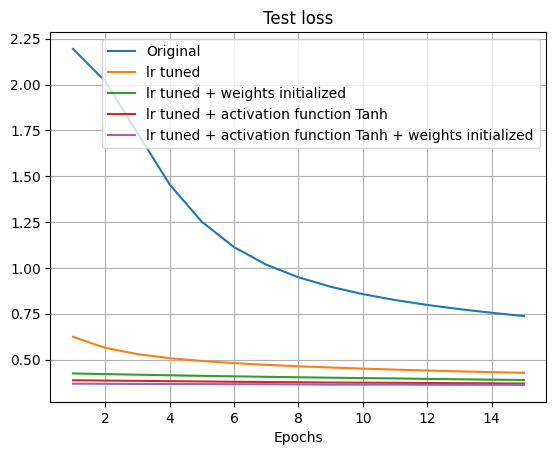

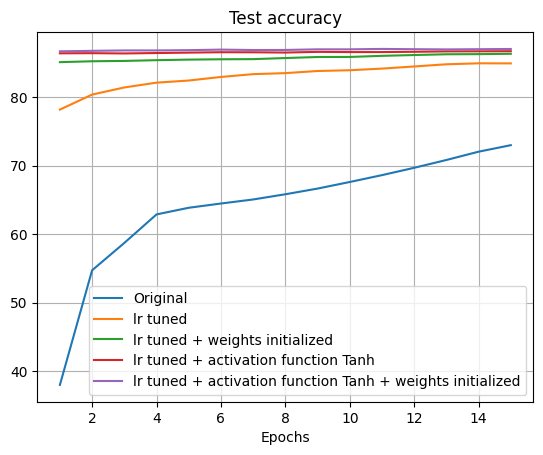

In [102]:
plot_5_histories(
    test_loss_history_or,
    test_loss_history,
    test_loss_history_wi,
    test_loss_history_af,
    test_loss_history_wi_af,
    "Test loss",
    ["Original", "lr tuned", "lr tuned + weights initialized", "lr tuned + activation function Tanh", "lr tuned + activation function Tanh + weights initialized"])

plot_5_histories(
    accuracy_history_or,
    accuracy_history,
    accuracy_history_wi,
    accuracy_history_af,
    accuracy_history_wi_af,
    "Test accuracy",
    ["Original", "lr tuned", "lr tuned + weights initialized", "lr tuned + activation function Tanh", "lr tuned + activation function Tanh + weights initialized"])

    

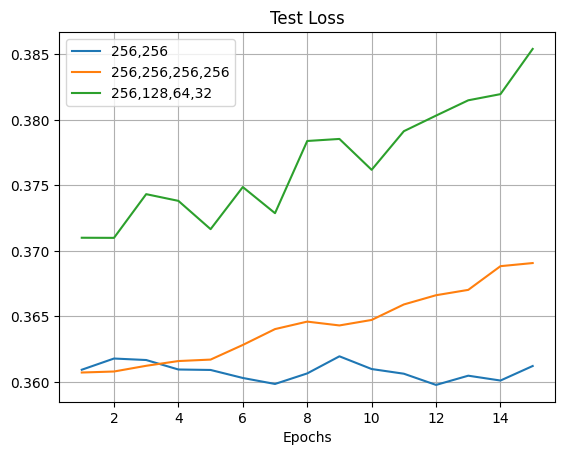

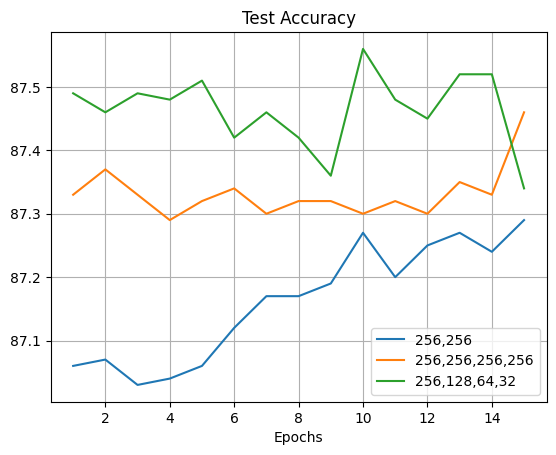

In [104]:
plot_3_histories(
    test_loss_history_1,
    test_loss_history_2,
    test_loss_history_3,
    "Test Loss",
    "256,256",
    "256,256,256,256",
    "256,128,64,32")

plot_3_histories(
    accuracy_history_1,
    accuracy_history_2,
    accuracy_history_3,
    "Test Accuracy",
    "256,256",
    "256,256,256,256",
    "256,128,64,32")